In [1]:
%pip install -q transformers accelerate peft \
    evaluate jiwer mlflow librosa soundfile \
    pandas numpy matplotlib seaborn tensorboard \
    safetensors dagshub


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydata-profiling 4.18.4 requires dacite<2,>=1.9, but you have dacite 1.6.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import gc
import re
import json
import uuid
import time
import random
import hashlib
import logging
import platform
import traceback
import soundfile as sf
from math import gcd

from pathlib import Path
from datetime import datetime, timezone
from dataclasses import dataclass, asdict
from typing import Dict, List, Optional

import transformers
import peft
import accelerate

import numpy as np
import pandas as pd
from scipy.signal import resample_poly

import torch
import torchaudio

import matplotlib.pyplot as plt
import seaborn as sns

import mlflow
import mlflow.pytorch

from transformers import (
    WhisperProcessor,
    WhisperForConditionalGeneration,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    TrainerCallback,
    EarlyStoppingCallback,
)

from peft import (
    LoraConfig,
    get_peft_model,
    PeftModel,
)

from jiwer import wer, cer

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s"
)

logger = logging.getLogger("whisper-lora")

In [3]:
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)

if torch.cuda.is_available():

    print("GPU count:", torch.cuda.device_count())

    for i in range(torch.cuda.device_count()):

        properties = torch.cuda.get_device_properties(i)

        print(f"\nGPU {i}")
        print("Name:", properties.name)
        print(
            "Memory:",
            round(properties.total_memory / 1024**3, 2),
            "GB"
        )

else:
    raise RuntimeError("CUDA GPU is required for this notebook.")

if torch.cuda.device_count() != 2:
    logger.warning(
        "Expected 2 GPUs. Actual GPU count: %s",
        torch.cuda.device_count()
    )

PyTorch: 2.11.0+cu130
CUDA available: True
CUDA version: 13.0
GPU count: 2

GPU 0
Name: Tesla T4
Memory: 14.56 GB

GPU 1
Name: Tesla T4
Memory: 14.56 GB


In [4]:
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

In [5]:
def get_environment_metadata():
    metadata = {
        "python_version": platform.python_version(),
        "platform": platform.platform(),
        "torch_version": torch.__version__,
        "cuda_version": torch.version.cuda,
        "gpu_count": torch.cuda.device_count(),
        "gpu_names": [],
    }

    for i in range(torch.cuda.device_count()):
        metadata["gpu_names"].append(
            torch.cuda.get_device_name(i)
        )

    metadata.update({
        "transformers_version": transformers.__version__,
        "peft_version": peft.__version__,
        "accelerate_version": accelerate.__version__,
        "mlflow_version": mlflow.__version__,
    })

    return metadata


ENVIRONMENT = get_environment_metadata()

print(json.dumps(ENVIRONMENT, indent=4))

{
    "python_version": "3.13.16",
    "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
    "torch_version": "2.11.0+cu130",
    "cuda_version": "13.0",
    "gpu_count": 2,
    "gpu_names": [
        "Tesla T4",
        "Tesla T4"
    ],
    "transformers_version": "5.20.2",
    "peft_version": "0.21.2",
    "accelerate_version": "1.15.0",
    "mlflow_version": "3.18.0"
}


In [6]:
PROJECT_NAME = "whisper-arabic-asr"

OUTPUT_ROOT = Path("/kaggle/working/whisper_experiments")

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

RUNS_DIR = OUTPUT_ROOT / "runs"
RUNS_DIR.mkdir(exist_ok=True)

COMPARISONS_DIR = OUTPUT_ROOT / "comparisons"
COMPARISONS_DIR.mkdir(exist_ok=True)

SAMPLE_RATE = 16000
LANGUAGE = "arabic"
LANGUAGE_CODE = "ar"
TASK = "transcribe"

In [7]:
MODEL_OPTIONS = {
    "tiny": "openai/whisper-tiny",
    "small": "openai/whisper-small",
}

MODEL_SIZE = "tiny"
MODEL_NAME = MODEL_OPTIONS[MODEL_SIZE]

print("Selected model:", MODEL_NAME)

Selected model: openai/whisper-tiny


In [8]:
DATASET_CONFIG = {
    "name": "common_voice_15",
    "path": "/kaggle/input/datasets/mothanaaldaigh/cv-15-ar",
    "config": "ar",
    "revision": None,
}

LORA_CONFIG = {
    "r": 16,
    "lora_alpha": 32,
    "lora_dropout": 0.05,
    "target_modules": [
        "q_proj",
        "v_proj",
    ],
    "bias": "none",
    "task_type": "SEQ_2_SEQ_LM",
}

print("Dataset:", DATASET_CONFIG["name"])
print("Dataset identifier:", DATASET_CONFIG["path"])
print("Dataset configuration:", DATASET_CONFIG["config"])

Dataset: common_voice_15
Dataset identifier: /kaggle/input/datasets/mothanaaldaigh/cv-15-ar
Dataset configuration: ar


In [9]:
LORA_CONFIG = {
    "r": 16,
    "lora_alpha": 32,
    "lora_dropout": 0.05,
    "target_modules": ["q_proj", "v_proj"],
    "bias": "none",
    "task_type": "SEQ_2_SEQ_LM",
}

#### All of these configs well be outsourced to params.yaml file

In [10]:
TRAINING_CONFIG = {
    "num_train_epochs": 5,
    "per_device_train_batch_size": 4,
    "per_device_eval_batch_size": 4,
    "gradient_accumulation_steps": 4,
    "learning_rate": 1e-4,
    "weight_decay": 0.01,
    "warmup_ratio": 0.1,
    "lr_scheduler_type": "cosine",
    "optim": "adamw_torch",
    "fp16": True,
    "gradient_checkpointing": True,
    "logging_steps": 25,
    "eval_strategy": "epoch",
    "save_strategy": "epoch",
    "save_total_limit": 2,
    "load_best_model_at_end": True,
    "metric_for_best_model": "wer",
    "greater_is_better": False,
    "predict_with_generate": True,
    "generation_max_length": 225,
    "dataloader_num_workers": 2,
    "report_to": "none",
}

In [11]:
EVALUATION_CONFIG = {
    "metrics": ["wer", "cer"],
    "normalize_arabic": True,
    "generation_max_length": 225,
    "num_beams": 1,
}

In [12]:
def generate_run_id(model_size, dataset_name, seed):
    # TS + US 
    timestamp = datetime.now(
        timezone.utc
    ).strftime("%Y%m%d_%H%M%S")
    unique_suffix = uuid.uuid4().hex[:8]

    return (
        f"{timestamp}_" f"{unique_suffix}_" f"whisper-{model_size}_" f"{dataset_name}_"f"seed-{seed}"
    )

DATASET_NAME = DATASET_CONFIG["name"]

RUN_ID = generate_run_id(
    MODEL_SIZE,
    DATASET_NAME,
    SEED
)

EXPERIMENT_NAME = (
    f"whisper-{MODEL_SIZE}-"
    f"{DATASET_NAME}-ar-lora"
)

# the output directory for each run
RUN_DIR = RUNS_DIR / RUN_ID

print("Run ID:", RUN_ID)
print("Experiment:", EXPERIMENT_NAME)
print("Run directory:", RUN_DIR)

Run ID: 20261126_170229_21b036ec_whisper-tiny_common_voice_15_seed-42
Experiment: whisper-tiny-common_voice_15-ar-lora
Run directory: /kaggle/working/whisper_experiments/runs/20261126_170229_21b036ec_whisper-tiny_common_voice_15_seed-42


In [13]:
DIRECTORIES = [
    "config", "adapter", "processor",
    "checkpoints", "metrics", "logs",
    "predictions", "report",
]

for directory in DIRECTORIES:
    (RUN_DIR / directory).mkdir(
        parents=True,
        exist_ok=True
    )

print("Experiment directory initialized.")

Experiment directory initialized.


In [14]:
EXPERIMENT_CONFIG = {
    "run_id": RUN_ID,
    "experiment_name": EXPERIMENT_NAME,
    "project": PROJECT_NAME,
    "model": {
        "name": MODEL_NAME,
        "size": MODEL_SIZE,
    },
    "dataset": {
        "name": DATASET_NAME,
        **DATASET_CONFIG,
    },
    "language": LANGUAGE,
    "language_code": LANGUAGE_CODE,
    "task": TASK,
    "sample_rate": SAMPLE_RATE,
    "seed": SEED,
    "lora": LORA_CONFIG,
    "training": TRAINING_CONFIG,
    "evaluation": EVALUATION_CONFIG,
    "environment": ENVIRONMENT,
}

with open(RUN_DIR / "config" / "hyperparameters.json", "w") as f:
    json.dump(EXPERIMENT_CONFIG, f, indent=4, default=str)

print("Configuration saved.")

Configuration saved.


In [15]:
import os
import dagshub

os.environ["DAGSHUB_USER_TOKEN"] = "306d3041674f88c5717db9af182bc1553884efbc"

dagshub.init(
    repo_owner="Muthana-Alsaigh",
    repo_name="my-first-repo",
    mlflow=True
)

❗❗❗ AUTHORIZATION REQUIRED ❗❗❗



Open the following link in your browser to authorize the client:
https://dagshub.com/login/oauth/authorize?state=9712b1f5-d088-45f6-98bf-3fce02abd03d&client_id=32b60ba385aa7cecf24046d8195a71c07dd345d9657977863b52e7748e0f0f28&middleman_request_id=013f3402702e75b458380f46bba01ae9469b3b30da56f9ac50d37f77eda1b47c




Output()

Accessing as Muthana-Alsaigh

Initialized MLflow to track repo "Muthana-Alsaigh/my-first-repo"

Repository Muthana-Alsaigh/my-first-repo initialized!

In [16]:
from kaggle_secrets import UserSecretsClient


user_secrets = UserSecretsClient()
MLFLOW_TRACKING_URI = user_secrets.get_secret("MLFLOW_TRACKING_URI")

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)

print("MLflow tracking URI configured.")

MLflow tracking URI configured.


In [17]:
MLFLOW_EXPERIMENT_NAME = "Whisper-Arabic-ASR"

client = mlflow.tracking.MlflowClient()

experiment = client.get_experiment_by_name(MLFLOW_EXPERIMENT_NAME)

# creation of the experment if it not exist
if experiment is None:
    experiment_id = client.create_experiment(MLFLOW_EXPERIMENT_NAME)
else:
    experiment_id = experiment.experiment_id
    
mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)

print("MLflow experiment ID:", experiment_id)

MLflow experiment ID: 0


In [18]:
run = client.create_run(
    experiment_id=experiment_id,
    tags={
        "mlflow.runName": EXPERIMENT_NAME,
        "project": PROJECT_NAME,
        "run_id": RUN_ID,
        "model_name": MODEL_SIZE,
        "dataset_name": DATASET_NAME,
        "language": LANGUAGE_CODE,
        "fine_tuning": "LoRA",
        "status": "INITIALIZED",
    }
)

MLFLOW_RUN_ID = run.info.run_id

print("MLflow Run ID:", MLFLOW_RUN_ID)

MLflow Run ID: d6a0df67f15f48699b9aa22e1dd0bceb


In [19]:
# transform every dectionery from nested to one-layer dectionary
def flatten_config(data, prefix=""):
    flattened = {}

    for key, value in data.items():
        full_key = (
            f"{prefix}.{key}"
            if prefix else key
        )

        if isinstance(value, dict):
            flattened.update(
                flatten_config(value, full_key)
            )

        elif isinstance(value, (list, tuple)):
            flattened[full_key] = json.dumps(value)

        else:
            flattened[full_key] = str(value)

    return flattened


def log_experiment_parameters():
    parameters = flatten_config(EXPERIMENT_CONFIG)
    
    # MLflow parameter keys have a maximum length.
    parameters = {
        k[:250]: v[:500] for k, v in parameters.items()
    }
    with mlflow.start_run(run_id=MLFLOW_RUN_ID):
        mlflow.log_params(parameters)
        mlflow.set_tags({
            "experiment_name": EXPERIMENT_NAME,
            "model": MODEL_NAME,
            "dataset": DATASET_NAME,
            "language": LANGUAGE_CODE,
        })

log_experiment_parameters()

🏃 View run whisper-tiny-common_voice_15-ar-lora at: https://dagshub.com/Muthana-Alsaigh/my-first-repo.mlflow/#/experiments/0/runs/d6a0df67f15f48699b9aa22e1dd0bceb
🧪 View experiment at: https://dagshub.com/Muthana-Alsaigh/my-first-repo.mlflow/#/experiments/0


In [20]:
environment_path = (RUN_DIR / "config" / "environment.json")

with open(environment_path, "w") as f:
    json.dump(ENVIRONMENT, f,indent=4)

with mlflow.start_run(run_id=MLFLOW_RUN_ID):
    mlflow.log_artifact(
        str(environment_path),
        artifact_path="configuration"
    )

🏃 View run whisper-tiny-common_voice_15-ar-lora at: https://dagshub.com/Muthana-Alsaigh/my-first-repo.mlflow/#/experiments/0/runs/d6a0df67f15f48699b9aa22e1dd0bceb
🧪 View experiment at: https://dagshub.com/Muthana-Alsaigh/my-first-repo.mlflow/#/experiments/0


In [28]:
DATA_ROOT = Path(DATASET_CONFIG["path"])
print(f"Dataset Root: {DATASET_ROOT}")

Dataset Root: /kaggle/input/datasets/mothanaaldaigh/cv-15-ar


In [29]:
def load_cv_tsv(tsv_path, audio_folder):
    df = pd.read_csv(tsv_path, sep="\t")

    # Common Voice columns
    df = df.rename(columns={
        "sentence": "text"
    })

    if "path" not in df.columns or "text" not in df.columns:
        raise ValueError(f"Missing path/text columns in {tsv_path}")

    df = df[["path", "text"]].dropna()


    df["audio_path"] = df["path"].map(lambda filename: DATA_ROOT / audio_folder / filename)
    df = df.rename(columns={"text": "text"})

    return df[["audio_path","text"]]



train_df = load_cv_tsv(DATA_ROOT / "train.tsv", "ar_train/ar_train_0")
dev_df   = load_cv_tsv(DATA_ROOT / "dev.tsv", "ar_dev/ar_dev_0")
test_df  = load_cv_tsv(DATA_ROOT / "test.tsv", "ar_dev/ar_dev_0")

display(train_df.head())


,audio_path,text
0,/kaggle/input/datasets/mothanaaldaigh/cv-15-ar...,وما كان ربك ليهلك القرى بظلم وأهلها مصلحون
1,/kaggle/input/datasets/mothanaaldaigh/cv-15-ar...,أقدر تعاونك معنا.
2,/kaggle/input/datasets/mothanaaldaigh/cv-15-ar...,وَلُوطًا إِذْ قَالَ لِقَوْمِهِ أَتَأْتُونَ الْ...
3,/kaggle/input/datasets/mothanaaldaigh/cv-15-ar...,فلما رأوا بأسنا قالوا آمنا بالله وحده وكفرنا ب...
4,/kaggle/input/datasets/mothanaaldaigh/cv-15-ar...,لمن هذا الكتاب؟


In [30]:
audio_path = train_df.iloc[0]["audio_path"]
print(audio_path)

audio_array, sampling_rate = sf.read(audio_path)

if audio_array.ndim == 2:
    audio_array = audio_array.mean(axis=1)

duration = len(audio_array) / sampling_rate

print("Sampling rate:", sampling_rate)
print("Duration:", duration)
print("Data type:", type(audio_array))
print("Audio shape:", audio_array.shape)

/kaggle/input/datasets/mothanaaldaigh/cv-15-ar/ar_train/ar_train_0/common_voice_ar_24032301.mp3
Sampling rate: 32000
Duration: 5.148
Data type: <class 'numpy.ndarray'>
Audio shape: (164736,)


In [31]:
def load_audio_16k(audio_path):
    audio, sr = sf.read(audio_path)

    # Convert stereo to mono
    if audio.ndim == 2:
        audio = audio.mean(axis=1)

    # Resample to SAMPLE_RATE
    if sr != SAMPLE_RATE:
        common = gcd(sr, SAMPLE_RATE)
        audio = resample_poly(
            audio,
            SAMPLE_RATE // common,
            sr // common
        )

    return audio.astype("float32")

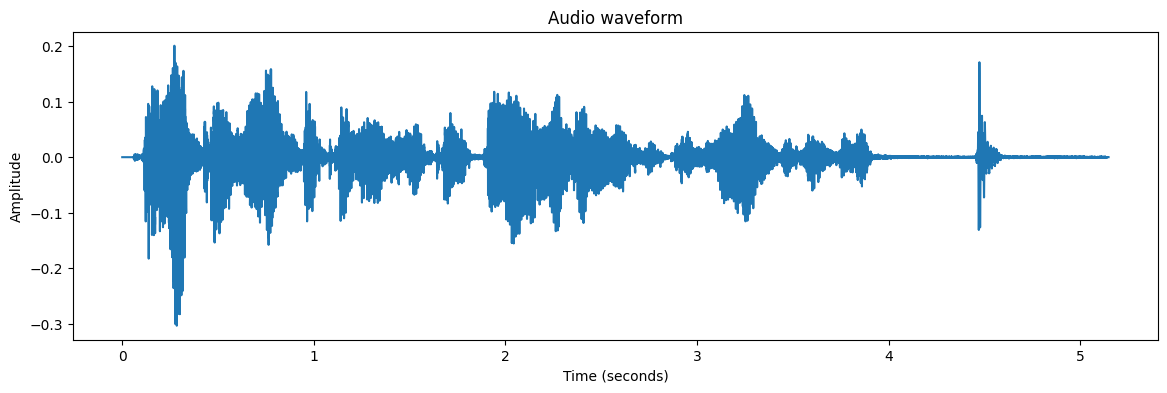

In [32]:
import numpy as np
import matplotlib.pyplot as plt

sr = SAMPLE_RATE
audio_array = load_audio_16k(audio_path)

plt.figure(figsize=(14, 4))
plt.plot(np.arange(len(audio_array)) / sr, audio_array)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Audio waveform")
plt.show()

In [36]:
dataset_metadata = {
    "dataset_name": DATASET_NAME,
    "dataset_path": DATASET_CONFIG["path"],
    "dataset_config": DATASET_CONFIG["config"],
    "train_samples": train_df.shape[0],
    "validation_samples": dev_df.shape[0],
    "test_samples": test_df.shape[0],
    "sample_rate": SAMPLE_RATE,
    "columns": list(train_df.columns),
}

dataset_metadata_path = (RUN_DIR / "config" / "dataset_config.json")

with open(dataset_metadata_path, "w") as f:
    json.dump(dataset_metadata, f, indent=4)


with mlflow.start_run(run_id=MLFLOW_RUN_ID):
    mlflow.log_params({
        "dataset.train_samples":
            dataset_metadata["train_samples"],
        "dataset.validation_samples":
            dataset_metadata["validation_samples"],
        "dataset.test_samples":
            dataset_metadata["test_samples"],
    })

    mlflow.log_artifact(
        str(dataset_metadata_path),
        artifact_path="configuration"
    )

🏃 View run whisper-tiny-common_voice_15-ar-lora at: https://dagshub.com/Muthana-Alsaigh/my-first-repo.mlflow/#/experiments/0/runs/d6a0df67f15f48699b9aa22e1dd0bceb
🧪 View experiment at: https://dagshub.com/Muthana-Alsaigh/my-first-repo.mlflow/#/experiments/0


In [37]:
ARABIC_NORMALIZATION_CONFIG = {
    "remove_diacritics": True,
    "remove_tatweel": False,
    "normalize_alef": True,
    "normalize_ya": False,
    "remove_punctuation": True,
}

In [38]:
ARABIC_DIACRITICS = re.compile(
    r"[\u0610-\u061A\u064B-\u065F\u0670\u06D6-\u06ED]"
)

ARABIC_PUNCTUATION = re.compile(
    r"[،؛؟!.,:;\"'()\[\]{}<>]"
)


def normalize_arabic(text):
    text = str(text).strip()
    
    if ARABIC_NORMALIZATION_CONFIG["remove_diacritics"]:
        text = ARABIC_DIACRITICS.sub("", text)

    if ARABIC_NORMALIZATION_CONFIG["remove_tatweel"]:
        text = text.replace("ـ", "")

    if ARABIC_NORMALIZATION_CONFIG["normalize_alef"]:
        text = re.sub(r"[أإآٱ]", "ا", text)

    if ARABIC_NORMALIZATION_CONFIG["normalize_ya"]:
        text = text.replace("ى", "ي")

    if ARABIC_NORMALIZATION_CONFIG["remove_punctuation"]:
        text = ARABIC_PUNCTUATION.sub("", text)

    text = re.sub(r"\s+", " ", text)
    return text.strip()

In [49]:
def normalize_example(example):
    example["text_normalized"] = normalize_arabic(example["text_original"])
    return example


def normalize_dataset_text(df):
    df = df.copy()
    df["text_normalized"] = df["text"].apply(normalize_arabic)
    return df


train_df_norm = normalize_dataset_text(train_df)
for i in range(10):
    print(train_df_norm.iloc[i]["text"])
    print(train_df_norm.iloc[i]["text_normalized"])

وما كان ربك ليهلك القرى بظلم وأهلها مصلحون
وما كان ربك ليهلك القرى بظلم واهلها مصلحون
أقدر تعاونك معنا.
اقدر تعاونك معنا
وَلُوطًا إِذْ قَالَ لِقَوْمِهِ أَتَأْتُونَ الْفَاحِشَةَ مَا سَبَقَكُمْ بِهَا مِنْ أَحَدٍ مِنَ الْعَالَمِينَ
ولوطا اذ قال لقومه اتاتون الفاحشة ما سبقكم بها من احد من العالمين
فلما رأوا بأسنا قالوا آمنا بالله وحده وكفرنا بما كنا به مشركين
فلما راوا باسنا قالوا امنا بالله وحده وكفرنا بما كنا به مشركين
لمن هذا الكتاب؟
لمن هذا الكتاب
إنه خطير للغاية.
انه خطير للغاية
بل متعت هؤلاء وآباءهم حتى جاءهم الحق ورسول مبين
بل متعت هؤلاء واباءهم حتى جاءهم الحق ورسول مبين
فَيَصِيرُ بِالرَّمْزِ سَائِرًا وَفِي الصُّحُفِ مُخَلَّدًا
فيصير بالرمز سائرا وفي الصحف مخلدا
أنا شريكك.
انا شريكك
لكن الرسول والذين آمنوا معه جاهدوا بأموالهم وأنفسهم وأولئك لهم الخيرات وأولئك هم المفلحون
لكن الرسول والذين امنوا معه جاهدوا باموالهم وانفسهم واولئك لهم الخيرات واولئك هم المفلحون


In [50]:

def validate_transcripts(df):
    empty_count = (
        df["text_normalized"].isna() | df["text_normalized"].str.strip().eq("")
    ).sum()

    print("Train empty transcripts:", empty_count)
    if empty_count:
        raise ValueError(
            f"Empty transcripts detected in train: {empty_count}"
        )

validate_transcripts(train_df_norm)

Train empty transcripts: 0


In [51]:
processor = WhisperProcessor.from_pretrained(
    MODEL_NAME,
    language=LANGUAGE,
    task=TASK,
)

processor.tokenizer.set_prefix_tokens(
    language=LANGUAGE,
    task=TASK,
)

print("Whisper processor loaded.")

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/494k [00:00<?, ?B/s]

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

Whisper processor loaded.


In [52]:
GENERATION_CONFIG = {
    "language": LANGUAGE,
    "task": TASK,
    "num_beams": EVALUATION_CONFIG["num_beams"],
    "max_length": EVALUATION_CONFIG[
        "generation_max_length"
    ],
}

In [53]:
def prepare_example(example):

    # Load local mp3 and resample to 16 kHz
    audio_array = load_audio_16k(
        example["audio_path"]
    )

    # Extract Whisper input features
    inputs = processor.feature_extractor(
        audio_array,
        sampling_rate=SAMPLE_RATE
    )

    # Tokenize normalized transcription
    labels = processor.tokenizer(
        example["text_normalized"]
    ).input_ids

    return {
        "input_features": inputs.input_features[0],
        "labels": labels
    }

In [56]:
example = prepare_example(train_df_norm.iloc[0])

print("Input features shape:")
print(example["input_features"].shape)

print("Labels:")
print(example["labels"])

Input features shape:
(80, 3000)
Labels:
[50258, 50272, 50359, 50363, 2407, 15042, 25961, 12602, 3555, 4117, 32239, 3224, 23275, 25062, 2288, 7578, 4724, 19913, 19528, 36764, 3224, 1211, 11296, 3714, 36520, 5016, 11536, 50257]


In [ ]:
from tqdm.auto import tqdm

bad_indices = {}

datasets = {
    "train": train_df_norm,
}

for split_name, split_df in datasets.items():
    bad_indices[split_name] = []

    print(f"\nChecking split: {split_name}")

    for idx in tqdm(range(len(split_df))):
        row = split_df.iloc[idx]

        try:
            audio_path = row["audio_path"]

            # Read and decode the WAV file
            audio, sr = sf.read(audio_path)

            # Validate that audio contains samples
            if audio.size == 0:
                raise ValueError("Empty audio file")

        except Exception as e:
            bad_indices[split_name].append(idx)

            print(f"\nFailed example: {idx}")
            print("Audio path:", row["audio_path"])
            print("Error:", str(e)[:200])

            # Print transcript for identification
            print("Transcript:", row["text"])

print("\nDiagnostic results:")

for split_name, indices in bad_indices.items():
    print(
        f"{split_name}: {len(indices)} corrupted examples"
    )


Checking split: train


  0%|          | 0/28406 [00:00<?, ?it/s]

In [66]:
import json

quality_report = {
    split: {
        "total_samples": len(dataset[split]),
        "rejected_samples": len(bad_indices[split]),
        "valid_samples": len(dataset[split]) - len(bad_indices[split]),
        "rejection_rate": len(bad_indices[split]) / len(dataset[split]),
        "errors": bad_indices[split]
    }
    for split in dataset
}

with open("data_quality_report.json", "w") as f:
    json.dump(quality_report, f, indent=4)

print(json.dumps(
    {k: {key: v for key, v in value.items() if key != "errors"}
     for k, value in quality_report.items()},
    indent=4
))

{
    "train": {
        "total_samples": 2104,
        "rejected_samples": 1,
        "valid_samples": 2103,
        "rejection_rate": 0.0004752851711026616
    },
    "validation": {
        "total_samples": 295,
        "rejected_samples": 0,
        "valid_samples": 295,
        "rejection_rate": 0.0
    },
    "test": {
        "total_samples": 428,
        "rejected_samples": 1,
        "valid_samples": 427,
        "rejection_rate": 0.002336448598130841
    }
}


In [61]:
from datasets import DatasetDict

clean_dataset = DatasetDict()

for split_name, split_dataset in dataset.items():

    bad = set(bad_indices[split_name])

    valid_indices = [
        i for i in range(len(split_dataset))
        if i not in bad
    ]

    clean_dataset[split_name] = split_dataset.select(valid_indices)

    print(
        f"{split_name}: "
        f"{len(split_dataset)} → {len(clean_dataset[split_name])}"
    )

train: 2104 → 2103
validation: 295 → 295
test: 428 → 427


In [67]:
import mlflow

for split, report in quality_report.items():
    mlflow.log_metrics({
        f"data.{split}.total": report["total_samples"],
        f"data.{split}.valid": report["valid_samples"],
        f"data.{split}.rejected": report["rejected_samples"],
        f"data.{split}.rejection_rate": report["rejection_rate"]
    })

mlflow.log_artifact("data_quality_report.json")

print("Data quality report logged to MLflow.")

Data quality report logged to MLflow.


In [65]:
processed_dataset = clean_dataset.map(
    prepare_example,
    remove_columns=clean_dataset["train"].column_names,
    desc="Extracting Whisper features"
)

print(processed_dataset)

Extracting Whisper features:   0%|          | 0/2103 [00:00<?, ? examples/s]

Extracting Whisper features:   0%|          | 0/295 [00:00<?, ? examples/s]

Extracting Whisper features:   0%|          | 0/427 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_features', 'labels'],
        num_rows: 2103
    })
    validation: Dataset({
        features: ['input_features', 'labels'],
        num_rows: 295
    })
    test: Dataset({
        features: ['input_features', 'labels'],
        num_rows: 427
    })
})


In [69]:
dataset_metadata = {
    "dataset_name": DATASET_NAME,
    "model_name": MODEL_NAME,
    "run_id": RUN_ID,
    "quality_report": {
        split: {
            "total": report["total_samples"],
            "valid": report["valid_samples"],
            "rejected": report["rejected_samples"]
        }
        for split, report in quality_report.items()
    }
}

with open("dataset_metadata.json", "w") as f:
    json.dump(dataset_metadata, f, indent=4)

mlflow.log_artifact("dataset_metadata.json")

In [70]:
sample = processed_dataset["train"][0]

print(
    "Input feature shape:",
    np.array(sample["input_features"]).shape
)

print(
    "Label length:",
    len(sample["labels"])
)

print(
    "Decoded labels:",
    processor.tokenizer.decode(
        sample["labels"]
    )
)

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Input feature shape: (80, 3000)
Label length: 60
Decoded labels: <|startoftranscript|><|ar|><|transcribe|><|notimestamps|>وعلى الرغم من ذلك فانها معضلة من الصعب حلها وستستغرق سنين طوال قبل ان نشهد بناء مفاعلات اندماج ذات نفع<|endoftext|>


In [71]:
from dataclasses import dataclass


@dataclass
class WhisperDataCollator:
    processor: WhisperProcessor

    def __call__(self, features):
        input_features = [
            {
                "input_features": feature["input_features"]
            }
            for feature in features
        ]

        batch = (
            self.processor.feature_extractor.pad(
                input_features,
                return_tensors="pt"
            )
        )

        label_features = [
            {
                "input_ids": feature["labels"]
            }
            for feature in features
        ]

        labels_batch = (
            self.processor.tokenizer.pad(
                label_features,
                return_tensors="pt"
            )
        )

        labels = labels_batch["input_ids"].masked_fill(
            labels_batch["attention_mask"].ne(1),
            -100
        )

        # Remove decoder start token if already present.
        if (
            labels[:, 0]
            == self.processor.tokenizer.bos_token_id
        ).all().item():

            labels = labels[:, 1:]

        batch["labels"] = labels

        return batch


data_collator = WhisperDataCollator(
    processor=processor
)

In [72]:
batch = data_collator([
    processed_dataset["train"][i]
    for i in range(4)
])

for key, value in batch.items():

    print(
        key,
        value.shape,
        value.dtype
    )

input_features torch.Size([4, 80, 3000]) torch.float32
labels torch.Size([4, 92]) torch.int64


In [ ]:
import os
import shutil

EXPERIMENT_DIR = "/kaggle/working/whisper_experiments"

if not os.path.exists(EXPERIMENT_DIR):
    raise FileNotFoundError(f"Directory not found: {EXPERIMENT_DIR}")

ZIP_PATH = shutil.make_archive(
    "/kaggle/working/whisper_experiments",
    "zip",
    root_dir="/kaggle/working",
    base_dir="whisper_experiments"
)

print("Archive created:", ZIP_PATH)
print(f"Size: {os.path.getsize(ZIP_PATH) / (1024**2):.2f} MB")